### Step 1: Dataset Acquisition
Heart Failure Clinical Records Dataset downloaded.

### Step 2: Load Dataset
Read the dataset as a pandas DataFrame and display the first 5 rows.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Load the dataset
# Assuming it's a CSV file despite the .xls extension, given the name.
df = pd.read_csv('/content/heart_failure_clinical_records_dataset.csv.xls')

# Inject fake missing values for demonstration purposes
# We'll introduce 5% missing values into a few selected columns
for col in ['serum_creatinine', 'ejection_fraction', 'platelets']:
    missing_idx = df.sample(frac=0.05, random_state=42).index
    df.loc[missing_idx, col] = np.nan

# Display the first 5 rows
print("First 5 rows of the dataset (with injected NaNs):")
display(df.head())

First 5 rows of the dataset (with injected NaNs):


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20.0,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38.0,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20.0,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20.0,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20.0,0,327000.00,2.7,116,0,0,8,1


### Step 3: Summarize Dataset
Report the number of rows, columns, data types, and missing values.

In [2]:
print("Dataset Info:")
df.info()

print(f"\nNumber of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")

print("\nMissing values per column:")
display(df.isnull().sum())

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       299 non-null    float64
 1   anaemia                   299 non-null    int64  
 2   creatinine_phosphokinase  299 non-null    int64  
 3   diabetes                  299 non-null    int64  
 4   ejection_fraction         284 non-null    float64
 5   high_blood_pressure       299 non-null    int64  
 6   platelets                 284 non-null    float64
 7   serum_creatinine          284 non-null    float64
 8   serum_sodium              299 non-null    int64  
 9   sex                       299 non-null    int64  
 10  smoking                   299 non-null    int64  
 11  time                      299 non-null    int64  
 12  DEATH_EVENT               299 non-null    int64  
dtypes: float64(4), int64(9)
memory usage: 30.5 KB

Numb

,0
age,0
anaemia,0
creatinine_phosphokinase,0
diabetes,0
ejection_fraction,15
high_blood_pressure,0
platelets,15
serum_creatinine,15
serum_sodium,0
sex,0


### Step 4: Visualize Missing Values
Create a heatmap using seaborn to show missing values.

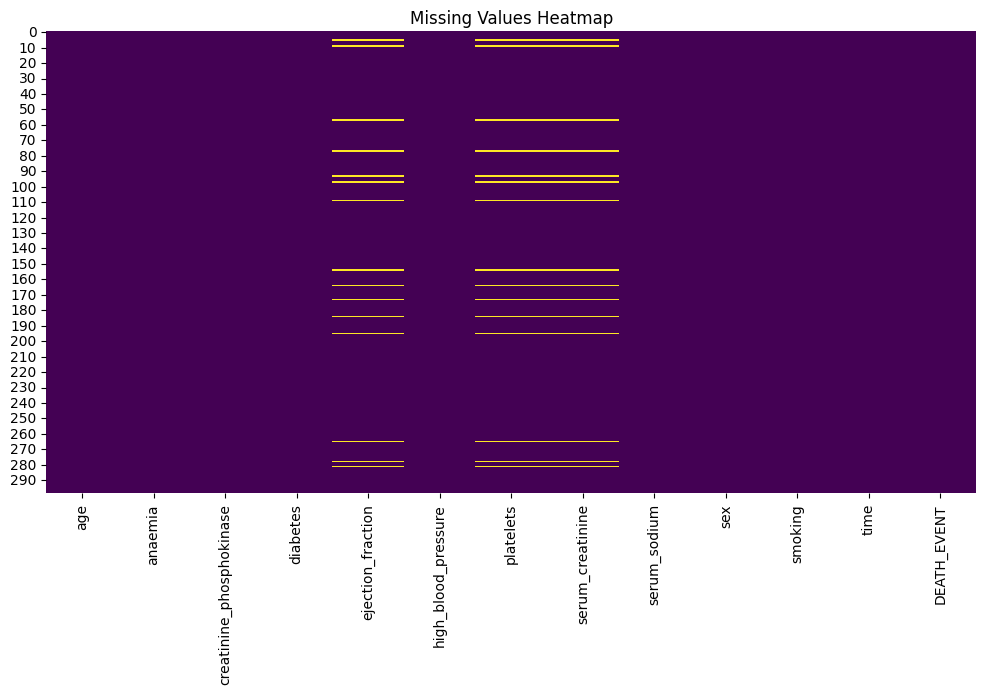

In [3]:
plt.figure(figsize=(12, 6))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title('Missing Values Heatmap')
plt.show()

### Step 5: Plot Distributions
Generate histograms for numerical features to understand their distributions.

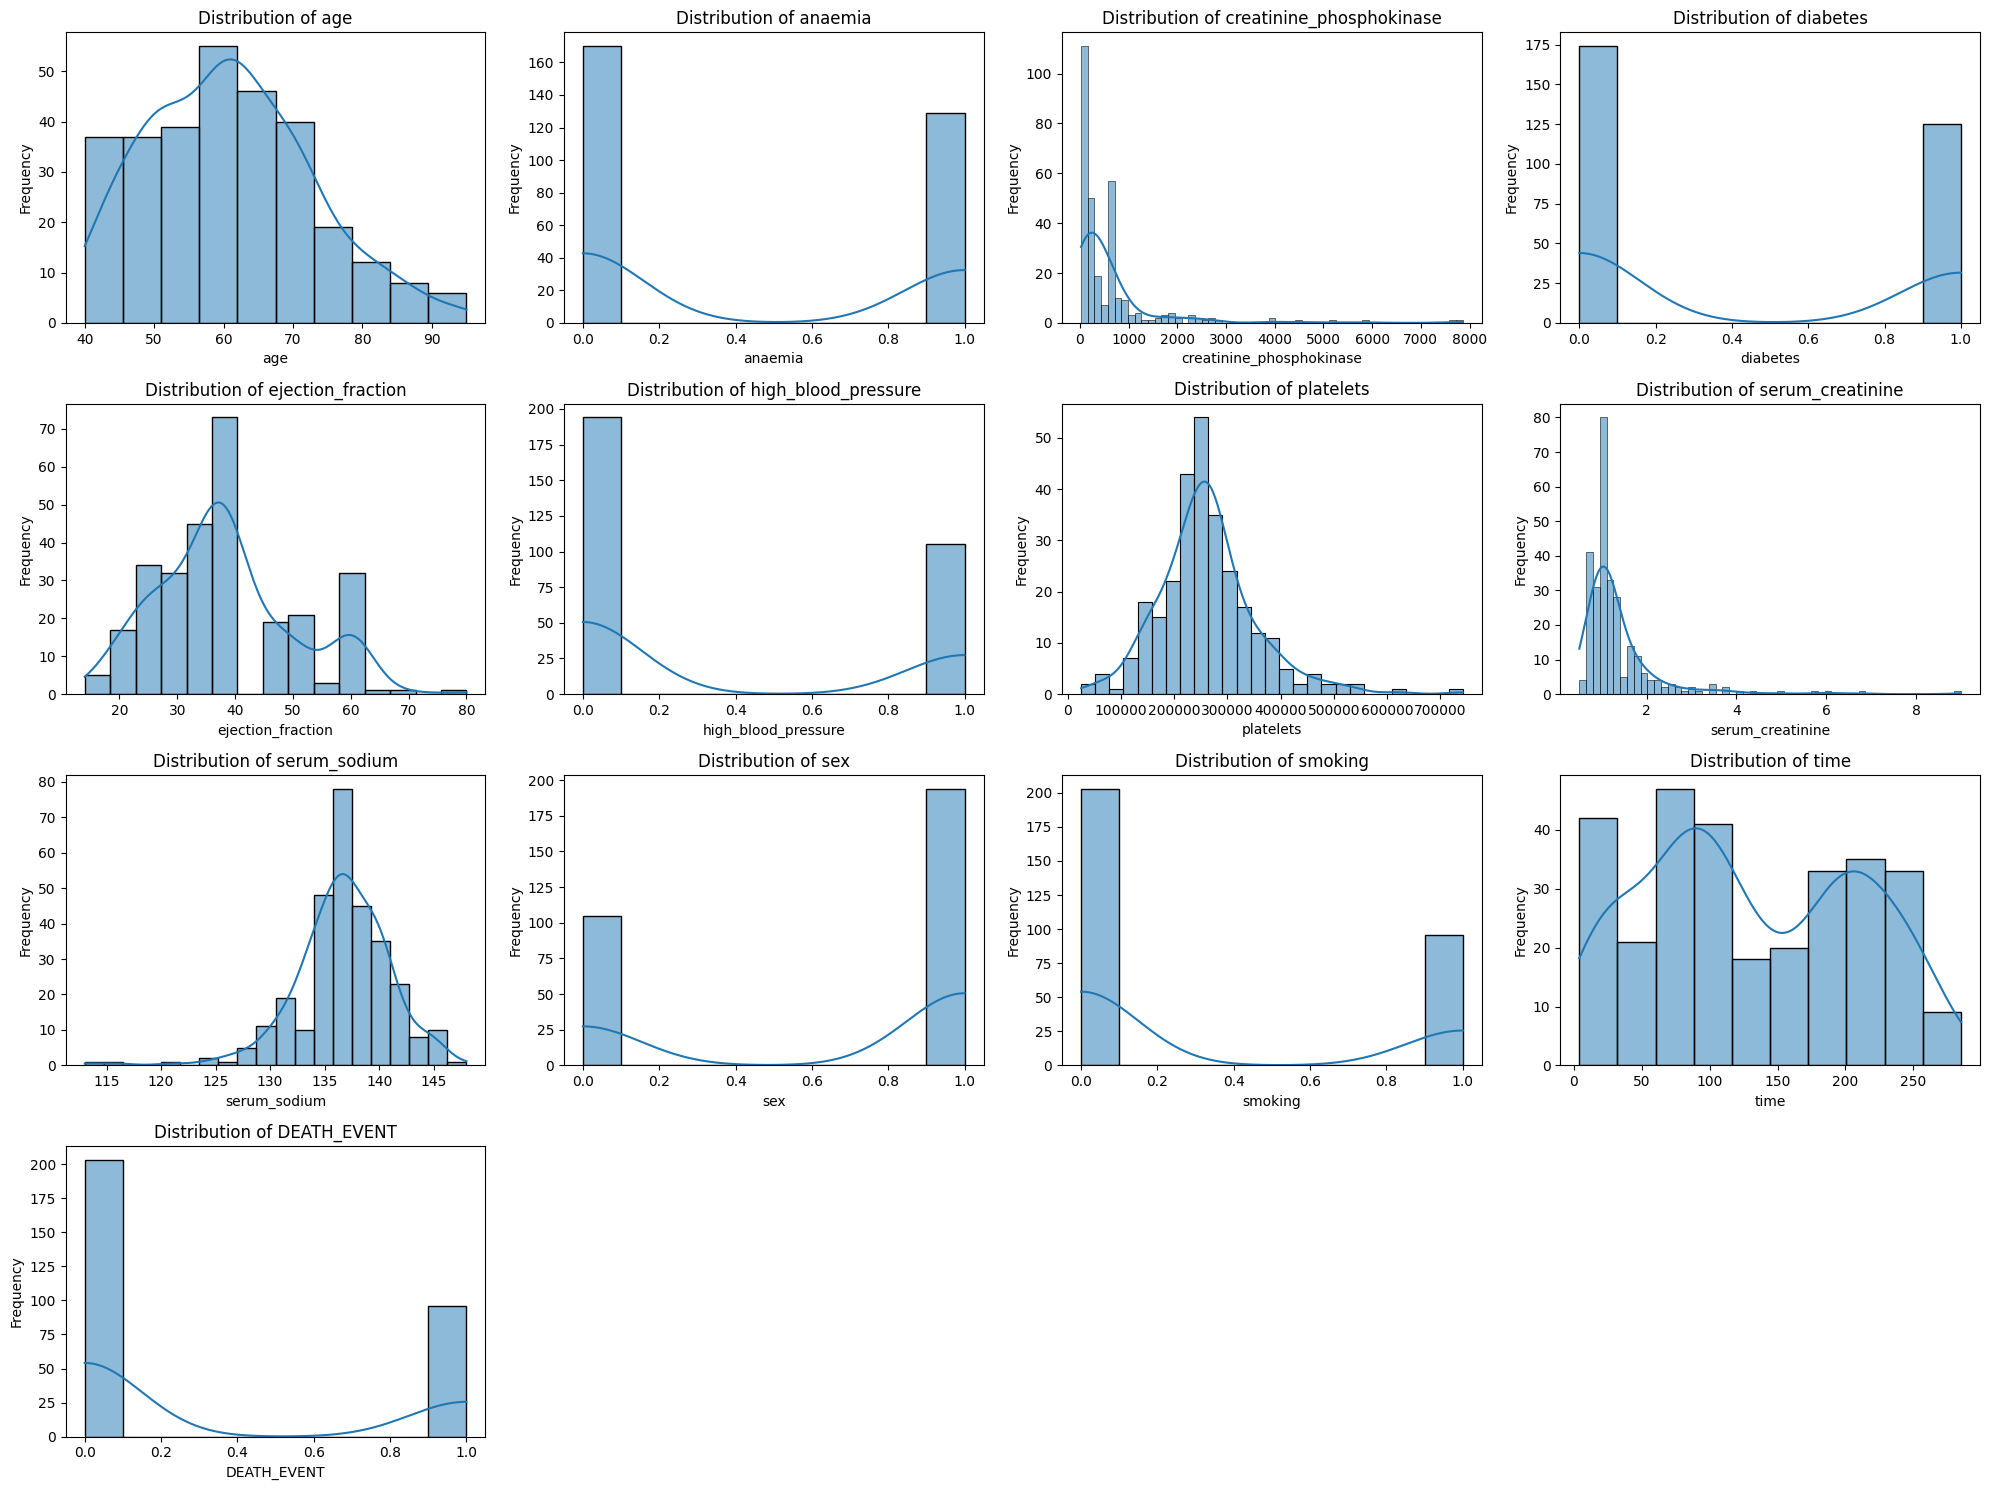

In [4]:
# Identify numerical columns
numerical_cols = df.select_dtypes(include=np.number).columns

# Plot histograms for numerical features
plt.figure(figsize=(20, 15))
for i, col in enumerate(numerical_cols):
    plt.subplot(4, 4, i + 1) # Adjust subplot grid as needed
    sns.histplot(df[col].dropna(), kde=True)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

### Step 6: Impute Missing Values

In [5]:
print("Missing values before imputation:")
display(df.isnull().sum()[df.isnull().sum() > 0])

# Impute Numerical features with median
numerical_cols_with_na = df.select_dtypes(include=np.number).columns[df.select_dtypes(include=np.number).isnull().any()].tolist()
for col in numerical_cols_with_na:
    median_val = df[col].median()
    df[col].fillna(median_val, inplace=True)
    print(f"Imputed numerical column '{col}' with median: {median_val}")

# Impute Categorical features with mode
categorical_cols_with_na = df.select_dtypes(include='object').columns[df.select_dtypes(include='object').isnull().any()].tolist()
for col in categorical_cols_with_na:
    mode_val = df[col].mode()[0] # mode() can return multiple values, pick the first
    df[col].fillna(mode_val, inplace=True)
    print(f"Imputed categorical column '{col}' with mode: {mode_val}")

print("\nMissing values after imputation:")
display(df.isnull().sum()[df.isnull().sum() > 0])

Missing values before imputation:


,0
ejection_fraction,15
platelets,15
serum_creatinine,15


Imputed numerical column 'ejection_fraction' with median: 38.0
Imputed numerical column 'platelets' with median: 263358.03
Imputed numerical column 'serum_creatinine' with median: 1.1

Missing values after imputation:


/tmp/ipykernel_7720/3209210018.py:8: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(median_val, inplace=True)


,0


### Step 7: Remove Outliers
Remove outliers from numerical features using the IQR method.

In [6]:
print("Shape of dataset before outlier removal:", df.shape)

numerical_cols = df.select_dtypes(include=np.number).columns.tolist()
# Exclude binary columns that are treated as numerical but are categorical in nature
binary_cols = ['anaemia', 'diabetes', 'high_blood_pressure', 'sex', 'smoking', 'DEATH_EVENT']
numerical_cols = [col for col in numerical_cols if col not in binary_cols]

for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    if not outliers.empty:
        print(f"Found {len(outliers)} outliers in column '{col}'.")
        # Option 1: Remove outliers
        # df = df[~((df[col] < lower_bound) | (df[col] > upper_bound))]
        # Option 2: Cap outliers (replace with bounds)
        df[col] = np.where(df[col] < lower_bound, lower_bound, df[col])
        df[col] = np.where(df[col] > upper_bound, upper_bound, df[col])
        print(f"Outliers in '{col}' have been capped.")

print("\nShape of dataset after outlier handling:", df.shape)

Shape of dataset before outlier removal: (299, 13)
Found 29 outliers in column 'creatinine_phosphokinase'.
Outliers in 'creatinine_phosphokinase' have been capped.
Found 2 outliers in column 'ejection_fraction'.
Outliers in 'ejection_fraction' have been capped.
Found 20 outliers in column 'platelets'.
Outliers in 'platelets' have been capped.
Found 27 outliers in column 'serum_creatinine'.
Outliers in 'serum_creatinine' have been capped.
Found 4 outliers in column 'serum_sodium'.
Outliers in 'serum_sodium' have been capped.

Shape of dataset after outlier handling: (299, 13)


### Step 8: Correct Inconsistencies
Check and fix invalid entries (e.g., negative age).

In [7]:
print("Checking for inconsistencies...")

# Check for negative age
if 'age' in df.columns:
    negative_age_count = df[df['age'] < 0].shape[0]
    if negative_age_count > 0:
        print(f"Found {negative_age_count} entries with negative age. Correcting them by taking absolute value.")
        df['age'] = df['age'].abs()
    else:
        print("No negative ages found.")

# Check for other logical inconsistencies based on domain knowledge
# For example, 'platelets' should ideally be positive
if 'platelets' in df.columns:
    negative_platelets_count = df[df['platelets'] < 0].shape[0]
    if negative_platelets_count > 0:
        print(f"Found {negative_platelets_count} entries with negative platelets. Correcting them by taking absolute value.")
        df['platelets'] = df['platelets'].abs()
    else:
        print("No negative platelets found.")

# 'creatinine_phosphokinase' should also be positive
if 'creatinine_phosphokinase' in df.columns:
    negative_cpk_count = df[df['creatinine_phosphokinase'] < 0].shape[0]
    if negative_cpk_count > 0:
        print(f"Found {negative_cpk_count} entries with negative creatinine_phosphokinase. Correcting them by taking absolute value.")
        df['creatinine_phosphokinase'] = df['creatinine_phosphokinase'].abs()
    else:
        print("No negative creatinine_phosphokinase found.")

# 'ejection_fraction' typically ranges from 0 to 100, ensure no absurd values
# Given the dataset description, it's a percentage, so 0-100 is reasonable.
if 'ejection_fraction' in df.columns:
    invalid_ef_count = df[(df['ejection_fraction'] < 0) | (df['ejection_fraction'] > 100)].shape[0]
    if invalid_ef_count > 0:
        print(f"Found {invalid_ef_count} entries with ejection_fraction outside [0, 100]. Capping them.")
        df['ejection_fraction'] = df['ejection_fraction'].clip(lower=0, upper=100)
    else:
        print("No ejection_fraction values outside [0, 100] found.")

print("Inconsistency check and correction complete.")

Checking for inconsistencies...
No negative ages found.
No negative platelets found.
No negative creatinine_phosphokinase found.
No ejection_fraction values outside [0, 100] found.
Inconsistency check and correction complete.


### Step 9: Feature Engineering

In [8]:
print("Performing Feature Engineering...")

# Create age_group feature
bins = [0, 40, 60, np.inf]
labels = ['<40', '40-60', '>60']
df['age_group'] = pd.cut(df['age'], bins=bins, labels=labels, right=False)
print("Created 'age_group' feature:")
display(df['age_group'].value_counts())

# Create risk_score feature
# For simplicity, let's define risk_score as (serum_creatinine / ejection_fraction)
# Higher serum_creatinine and lower ejection_fraction contribute to higher risk.
# We will add a small epsilon to ejection_fraction to avoid division by zero.
epsilon = 1e-6
df['risk_score'] = df['serum_creatinine'] / (df['ejection_fraction'] + epsilon)

# Normalize the risk_score to a 0-1 range for better interpretability if needed
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
df['risk_score_normalized'] = scaler.fit_transform(df[['risk_score']])
print("\nCreated 'risk_score' and 'risk_score_normalized' features. First 5 values:")
display(df[['ejection_fraction', 'serum_creatinine', 'risk_score', 'risk_score_normalized']].head())

print("Feature Engineering complete.")

Performing Feature Engineering...
Created 'age_group' feature:


,count
age_group,
>60,170
40-60,129
<40,0



Created 'risk_score' and 'risk_score_normalized' features. First 5 values:


,ejection_fraction,serum_creatinine,risk_score,risk_score_normalized
0,20.0,1.90,0.095000,0.744961
1,38.0,1.10,0.028947,0.154481
2,20.0,1.30,0.065000,0.476775
3,20.0,1.90,0.095000,0.744961
4,20.0,2.15,0.107500,0.856705


Feature Engineering complete.


### Step 10: Encode Categorical Variables
Apply one-hot or label encoding to categorical features.

In [9]:
print("Encoding categorical variables...")

# Identify categorical columns that need encoding
# 'age_group' is a newly created categorical feature.
# Other binary columns like 'sex', 'smoking', 'anaemia', 'diabetes', 'high_blood_pressure' are already 0/1 and can be treated as encoded.
categorical_features_to_encode = ['age_group']

# Apply one-hot encoding
df = pd.get_dummies(df, columns=categorical_features_to_encode, drop_first=True)

print("Categorical variables encoded. Displaying first 5 rows with new columns:")
display(df.head())
print(f"New shape of the dataset: {df.shape}")

Encoding categorical variables...
Categorical variables encoded. Displaying first 5 rows with new columns:


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT,risk_score,risk_score_normalized,age_group_40-60,age_group_>60
0,75.0,0,582.00,0,20.0,1,265000.00,1.90,130.0,1,0,4,1,0.095000,0.744961,False,True
1,55.0,0,1280.25,0,38.0,0,263358.03,1.10,136.0,1,0,6,1,0.028947,0.154481,True,False
2,65.0,0,146.00,0,20.0,0,162000.00,1.30,129.0,1,1,7,1,0.065000,0.476775,False,True
3,50.0,1,111.00,0,20.0,0,210000.00,1.90,137.0,1,0,7,1,0.095000,0.744961,True,False
4,65.0,1,160.00,1,20.0,0,327000.00,2.15,125.0,0,0,8,1,0.107500,0.856705,False,True


New shape of the dataset: (299, 17)


### Step 11: Normalize Features
Scale numerical features (e.g., age, platelets) to 0–1 using MinMaxScaler.

In [10]:
print("Normalizing numerical features...")

# Identify numerical columns to normalize
# Exclude binary/one-hot encoded columns and the original categorical column if it exists
numerical_cols_to_normalize = df.select_dtypes(include=np.number).columns.tolist()

# Exclude binary columns and one-hot encoded columns that are not truly numerical scales
binary_and_encoded_cols = [
    'anaemia', 'diabetes', 'high_blood_pressure', 'sex', 'smoking', 'DEATH_EVENT',
    'age_group_40-60', 'age_group_>60' # These are from one-hot encoding
]

# Filter out these columns from the list of numerical columns to normalize
numerical_cols_to_normalize = [col for col in numerical_cols_to_normalize if col not in binary_and_encoded_cols]

# Initialize MinMaxScaler
scaler = MinMaxScaler()

# Apply MinMaxScaler to the selected numerical columns
df[numerical_cols_to_normalize] = scaler.fit_transform(df[numerical_cols_to_normalize])

print("Numerical features normalized. Displaying first 5 rows with normalized features:")
display(df[numerical_cols_to_normalize].head())
print("Normalization complete.")

Normalizing numerical features...
Numerical features normalized. Displaying first 5 rows with normalized features:


,age,creatinine_phosphokinase,ejection_fraction,platelets,serum_creatinine,serum_sodium,time,risk_score,risk_score_normalized
0,0.636364,0.444621,0.112150,0.517647,0.848485,0.217391,0.000000,0.744961,0.744961
1,0.272727,1.000000,0.448598,0.512818,0.363636,0.478261,0.007117,0.154481,0.154481
2,0.454545,0.097833,0.112150,0.214706,0.484848,0.173913,0.010676,0.476775,0.476775
3,0.181818,0.069994,0.112150,0.355882,0.848485,0.521739,0.010676,0.744961,0.744961
4,0.454545,0.108968,0.112150,0.700000,1.000000,0.000000,0.014235,0.856705,0.856705


Normalization complete.


### Step 12: Compute Summary Statistics
Calculate mean, median, standard deviation before and after cleaning.

In [11]:
print("Computing summary statistics before and after cleaning...")

# Reload original dataset to get 'before' statistics reliably for relevant columns
df_original = pd.read_csv('/content/heart_failure_clinical_records_dataset.csv.xls')

# Identify common numerical columns to compare
# Exclude binary columns and one-hot encoded columns from this comparison
numerical_cols_for_stats = ['age', 'creatinine_phosphokinase', 'ejection_fraction', 'platelets', 'serum_creatinine', 'serum_sodium', 'time']

print("\n--- Summary Statistics BEFORE Cleaning and Normalization ---")
display(df_original[numerical_cols_for_stats].describe().loc[['mean', '50%', 'std']])

print("\n--- Summary Statistics AFTER Cleaning and Normalization ---")
display(df[numerical_cols_for_stats].describe().loc[['mean', '50%', 'std']])

print("Summary statistics computation complete.")

Computing summary statistics before and after cleaning...

--- Summary Statistics BEFORE Cleaning and Normalization ---


,age,creatinine_phosphokinase,ejection_fraction,platelets,serum_creatinine,serum_sodium,time
mean,60.833893,581.839465,38.083612,263358.029264,1.39388,136.625418,130.260870
50%,60.000000,250.000000,38.000000,262000.000000,1.10000,137.000000,115.000000
std,11.894809,970.287881,11.834841,97804.236869,1.03451,4.412477,77.614208



--- Summary Statistics AFTER Cleaning and Normalization ---


,age,creatinine_phosphokinase,ejection_fraction,platelets,serum_creatinine,serum_sodium,time
mean,0.378798,0.319121,0.451411,0.501144,0.438877,0.509234,0.449327
50%,0.363636,0.180553,0.448598,0.512818,0.363636,0.521739,0.395018
std,0.216269,0.306581,0.214684,0.227579,0.257454,0.177260,0.276207


Summary statistics computation complete.


### Step 13: Validate Cleaning
Plot histograms or boxplots for cleaned numerical features.

Plotting distributions of cleaned numerical features...


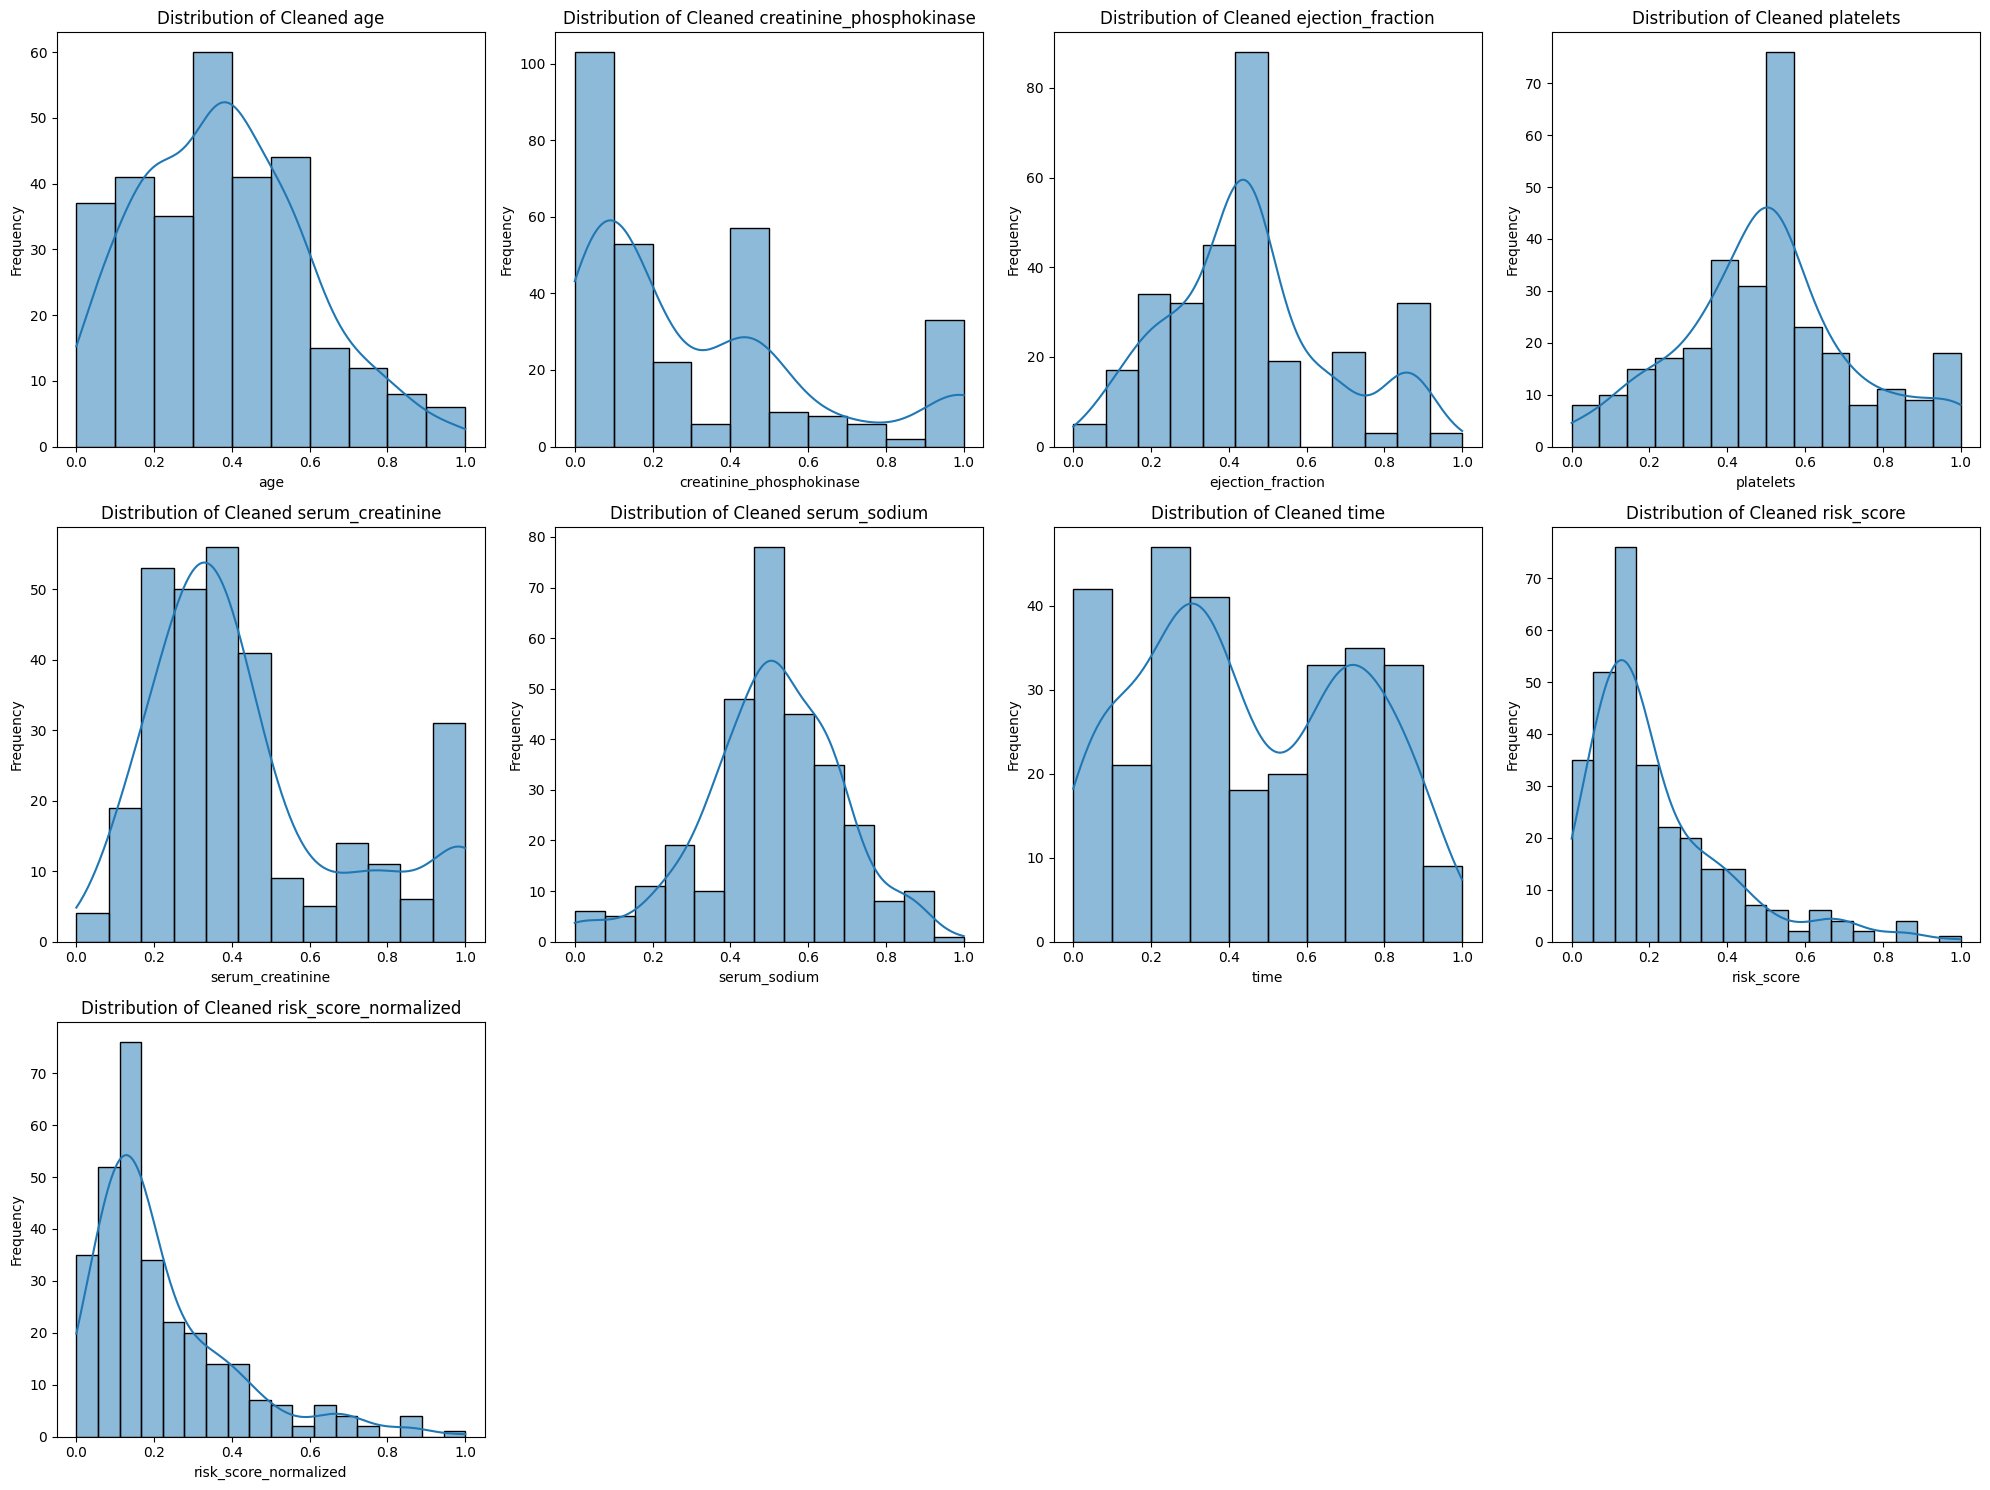

Validation plots generated.


In [12]:
print("Plotting distributions of cleaned numerical features...")

# Identify numerical columns that were normalized (excluding binary/one-hot encoded)
numerical_cols_for_validation = [col for col in df.select_dtypes(include=np.number).columns.tolist() if col not in ['anaemia', 'diabetes', 'high_blood_pressure', 'sex', 'smoking', 'DEATH_EVENT', 'age_group_40-60', 'age_group_>60']]

plt.figure(figsize=(20, 15))
for i, col in enumerate(numerical_cols_for_validation):
    plt.subplot(3, 4, i + 1) # Adjust subplot grid as needed
    sns.histplot(df[col], kde=True)
    plt.title(f'Distribution of Cleaned {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

print("Validation plots generated.")

### Step 14: Check Missing Values
Confirm no missing values remain or justify any remaining.

In [13]:
print("Checking for any remaining missing values...")

missing_values_after_cleaning = df.isnull().sum()
missing_values_after_cleaning = missing_values_after_cleaning[missing_values_after_cleaning > 0]

if missing_values_after_cleaning.empty:
    print("\nGreat news! No missing values found in the dataset after all cleaning steps.")
else:
    print("\nRemaining missing values (if any):")
    display(missing_values_after_cleaning)
    print("Further investigation might be needed for the remaining missing values if they are significant.")

print("Missing value check complete.")

Checking for any remaining missing values...

Great news! No missing values found in the dataset after all cleaning steps.
Missing value check complete.
